# 😎 Adding Sunglasses for a Cool New Look

This notebook detects a face in a passport-size photo using **OpenCV** and overlays a sunglasses image on the eyes.

**Steps**
1. Load the face photo and the sunglasses image
2. Remove the white background from the sunglasses
3. Detect the face and eyes (Haar cascades)
4. Resize and position the sunglasses
5. Blend them onto the face and save the result

**Libraries:** Python, OpenCV, NumPy, Matplotlib

## 1. Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.13.0


## 2. Load the images

Put your photo in the `images` folder as `face.png`, and the sunglasses as `sunglasses.png` (or change the paths below).

Face image shape    : (1018, 680, 3)
Sunglasses shape    : (342, 912, 4)


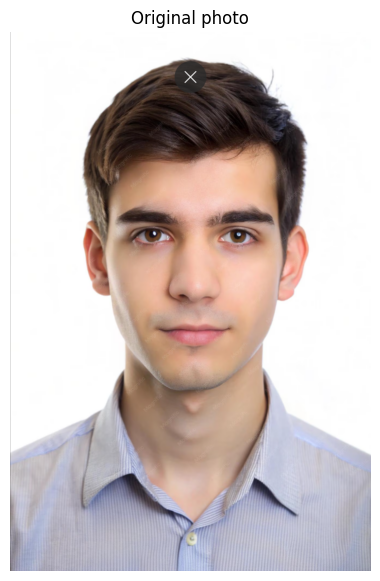

In [2]:
FACE_PATH = "images/face.png"
GLASSES_PATH = "images/sunglasses.png"

face_img = cv2.imread(FACE_PATH)                          # BGR, 3 channels
glasses_raw = cv2.imread(GLASSES_PATH, cv2.IMREAD_UNCHANGED)

assert face_img is not None, f"Could not read {FACE_PATH}"
assert glasses_raw is not None, f"Could not read {GLASSES_PATH}"

print("Face image shape    :", face_img.shape)
print("Sunglasses shape    :", glasses_raw.shape)

def show(img, title="", bgr=True, size=(5, 7)):
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if bgr else img)
    plt.title(title)
    plt.axis("off")
    plt.show()

show(face_img, "Original photo")

## 3. Prepare the sunglasses (remove the white background)

The sunglasses image has a white background, so we build our own transparency mask: every near-white pixel becomes transparent (this also clears the gaps around the nose bridge). The lenses are blue, so they are not affected.

Cropped sunglasses shape: (276, 754, 4)


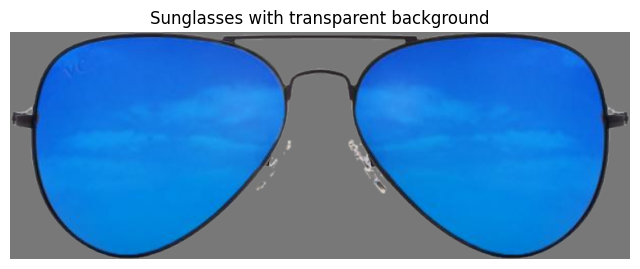

In [3]:
def make_transparent(img, white_thresh=225):
    """Return a BGRA image where white pixels are transparent."""
    img = img[3:-3, 3:-3]                                  # trim edge artefacts (stray line at the border)
    bgr = img[:, :, :3].copy()

    near_white = np.all(bgr >= white_thresh, axis=2)
    alpha = np.where(near_white, 0, 255).astype(np.uint8)

    alpha = cv2.erode(alpha, np.ones((3, 3), np.uint8))   # remove white halo around the frame
    alpha = cv2.GaussianBlur(alpha, (3, 3), 0)            # soften jagged edges
    return np.dstack([bgr, alpha])

def crop_to_content(bgra):
    """Crop away fully transparent borders."""
    ys, xs = np.where(bgra[:, :, 3] > 10)
    return bgra[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

glasses = crop_to_content(make_transparent(glasses_raw))
print("Cropped sunglasses shape:", glasses.shape)

# preview on a grey background so the transparency is visible
preview = np.full((*glasses.shape[:2], 3), 120, np.uint8)
a = glasses[:, :, 3:4] / 255.0
preview = (glasses[:, :, :3] * a + preview * (1 - a)).astype(np.uint8)
show(preview, "Sunglasses with transparent background", size=(8, 3))

## 4. Detect the face and eyes

We use OpenCV's pre-trained **Haar cascade** classifiers.

Face box (x, y, w, h): (np.int32(123), np.int32(209), np.int32(451), np.int32(451))


Eyes found: 2


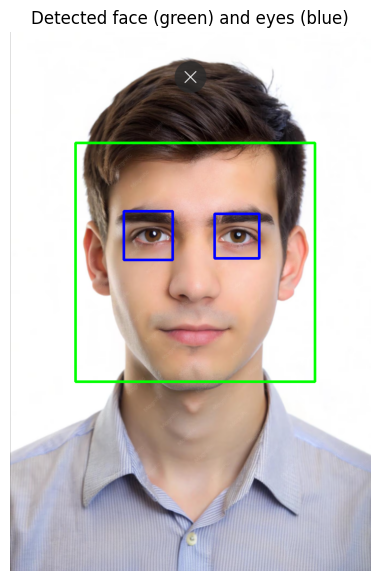

In [4]:
gray = cv2.cvtColor(face_img, cv2.COLOR_BGR2GRAY)

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
eye_cascade  = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_eye.xml")

faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(80, 80))
assert len(faces) > 0, "No face detected - try a clearer, front-facing photo."

# if several faces are found, use the biggest one
x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
print("Face box (x, y, w, h):", (x, y, w, h))

# look for eyes only in the upper part of the face (avoids mouth/nose false hits)
roi_gray = gray[y:y + int(h * 0.6), x:x + w]
eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=5, minSize=(w // 10, w // 10))
print("Eyes found:", len(eyes))

# draw the detections
debug = face_img.copy()
cv2.rectangle(debug, (x, y), (x + w, y + h), (0, 255, 0), 3)
for (ex, ey, ew, eh) in eyes:
    cv2.rectangle(debug, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 0, 0), 3)
show(debug, "Detected face (green) and eyes (blue)")

## 5. Work out where the sunglasses should go

If two eyes are detected, the sunglasses are centred between them and sized from the distance between the eyes. If not, we fall back to standard face proportions.

In [5]:
if len(eyes) >= 2:
    # take the two largest detections, ordered left to right
    two = sorted(sorted(eyes, key=lambda e: e[2] * e[3], reverse=True)[:2], key=lambda e: e[0])
    centres = [(x + ex + ew // 2, y + ey + eh // 2) for ex, ey, ew, eh in two]
    eye_dist = centres[1][0] - centres[0][0]
    cx = (centres[0][0] + centres[1][0]) // 2
    cy = (centres[0][1] + centres[1][1]) // 2
    glasses_w = int(eye_dist * 2.4)
    print("Placement: from detected eyes")
else:
    cx = x + w // 2
    cy = y + int(h * 0.39)
    glasses_w = int(w * 0.9)
    print("Placement: from face proportions (eyes not found)")

scale = glasses_w / glasses.shape[1]
glasses_h = int(glasses.shape[0] * scale)
glasses_resized = cv2.resize(glasses, (glasses_w, glasses_h), interpolation=cv2.INTER_AREA)

x1, y1 = cx - glasses_w // 2, cy - glasses_h // 2
print("Sunglasses size:", (glasses_w, glasses_h), "| top-left:", (x1, y1))

Placement: from detected eyes
Sunglasses size: (400, 146) | top-left: (np.int32(143), np.int32(311))


## 6. Overlay the sunglasses (alpha blending)

`result = glasses × alpha + photo × (1 − alpha)`

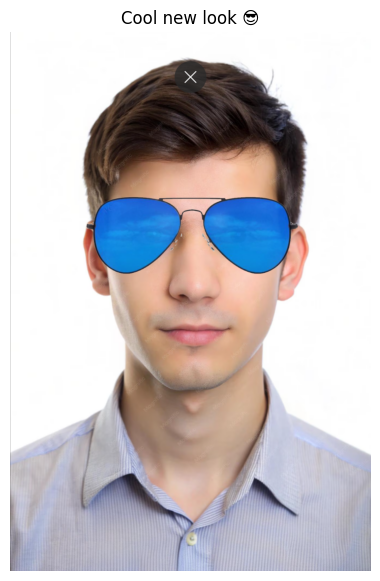

In [6]:
def overlay(background, fg_bgra, x, y, opacity=0.95):
    out = background.copy()
    H, W = out.shape[:2]
    fh, fw = fg_bgra.shape[:2]

    # clip if the overlay goes outside the photo
    x0, y0 = max(x, 0), max(y, 0)
    x1_, y1_ = min(x + fw, W), min(y + fh, H)
    if x0 >= x1_ or y0 >= y1_:
        return out

    fg = fg_bgra[y0 - y:y1_ - y, x0 - x:x1_ - x]
    alpha = (fg[:, :, 3:4] / 255.0) * opacity
    roi = out[y0:y1_, x0:x1_]
    out[y0:y1_, x0:x1_] = (fg[:, :, :3] * alpha + roi * (1 - alpha)).astype(np.uint8)
    return out

result = overlay(face_img, glasses_resized, x1, y1)
show(result, "Cool new look 😎")

## 7. Before vs After and save

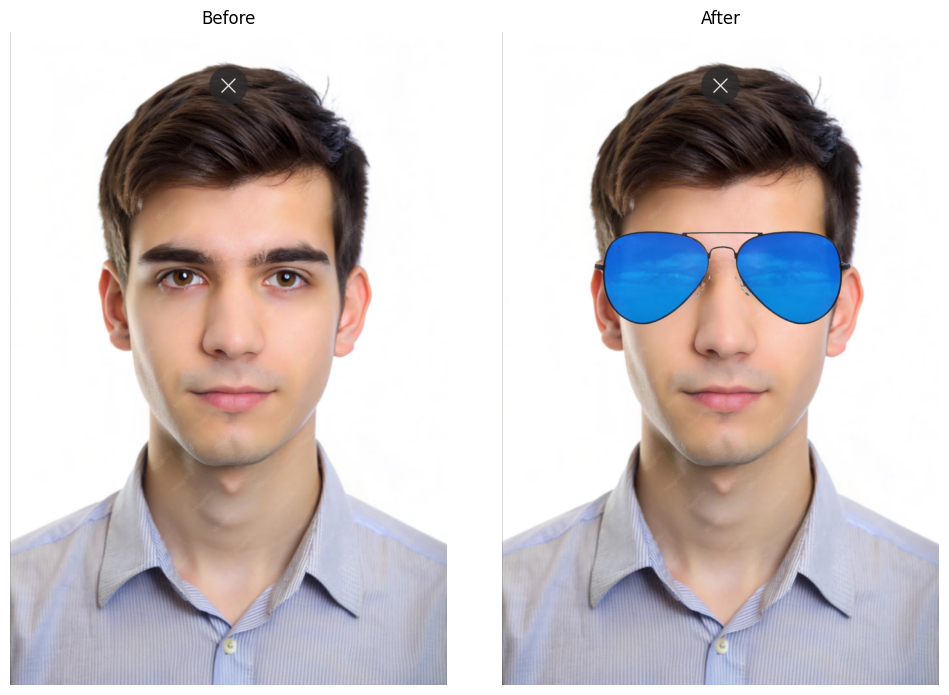

Saved: output_with_sunglasses.png


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow(cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Before"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB));   ax[1].set_title("After");  ax[1].axis("off")
plt.tight_layout()
plt.show()

cv2.imwrite("output_with_sunglasses.png", result)
print("Saved: output_with_sunglasses.png")

## Conclusion

Using OpenCV Haar cascades we detected the face and eyes, removed the white background from the sunglasses, resized them to fit the eye distance, and blended them onto the photo with alpha blending.

**Ideas to extend:** try different sunglasses styles, rotate the glasses to match head tilt using the eye angle, or run it on a webcam feed.